In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,"We deal with the \textit{selective classification} problem (supervised-learning problem with a rejection option), where we want to achieve the best performance at a certain level of coverage of the data. We transform the original $m$-class classification problem to $(m+1)$-class where the $(m+1)$-th class represents the model abstaining from making a prediction due to uncertainty. Inspired by portfolio theory, we propose a loss function for the selective classification problem based on the doubling rate of gambling. We show that minimizing this loss function has a natural interpretation as maximizing the return of a \textit{horse race}, where a player aims to balance between betting on an outcome (making a prediction) when confident and reserving one's winnings (abstaining) when not confident. This loss function allows us to train neural networks and characterize the uncertainty of prediction in an end-to-end fashion. In comparison with previous methods, our method requires almost no modification to the model inference algorithm or neural architecture. Experimentally, we show that our method can identify both uncertain and outlier data points, and achieves strong results on SVHN and CIFAR10 at various coverages of the data.","Recent advances in deep learning have led to remarkable improvements in the performance of neural networks. However, the lack of transparency in these models limits our ability to understand and improve upon their behavior. In this work, we develop a novel technique to visualize the internal dynamics of deep neural networks during training. By applying a continuous time dynamical systems interpretation to the training process, we are able to track the evolution of the network's parameters over time. We then apply this technique to a variety of deep learning models, including fully connected networks, convolutional networks, and recurrent networks. Our results reveal interesting phenomena such as the emergence of periodic oscillations, bifurcations, and chaotic behavior. Moreover, we show that these behaviors are indicators of the generalization capabilities of the network.",0.3190,0.0432,0.1718,0.8522,0.8116,0.8314,2,8,8,69,False,66-70
1,1102,2958885478,"Traditional 3D Convolutional Neural Networks (CNNs) are computationally expensive, memory intensive, prone to overfit, and most importantly, there is a need to improve their feature learning capabilities. To address these issues, we propose Rectified Local Phase Volume (ReLPV) block, an efficient alternative to the standard 3D convolutional layer. The ReLPV block extracts the phase in a 3D local neighborhood (e.g., 3x3x3) of each position of the input map to obtain the feature maps. The phase is extracted by computing 3D Short Term Fourier Transform (STFT) at multiple fixed low frequency points in the 3D local neighborhood of each position. These feature maps at different frequency points are then linearly combined after passing them through an activation function. The ReLPV block provides significant parameter savings of at least, 3^3 to 13^3 times compared to the standard 3D convolutional layer with the filter sizes 3x3x3 to 13x13x13, respectively. We show that the feature learning capabilities of the ReLPV block are significantly better than the standard 3D convolutional layer. Furthermore, it produces consistently better results across different 3D data representations. We achieve state-of-the-art accuracy on the volumetric ModelNet10 and ModelNet40 datasets while utilizing only 11% parameters of the current state-of-the-art. We also improve the state-of-the-art on the UCF-101 split-1 action recognition dataset by 5.68% (when trained from scratch) while using only 15% of the parameters of the state-of-the-art. The project webpage is avail

In [13]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


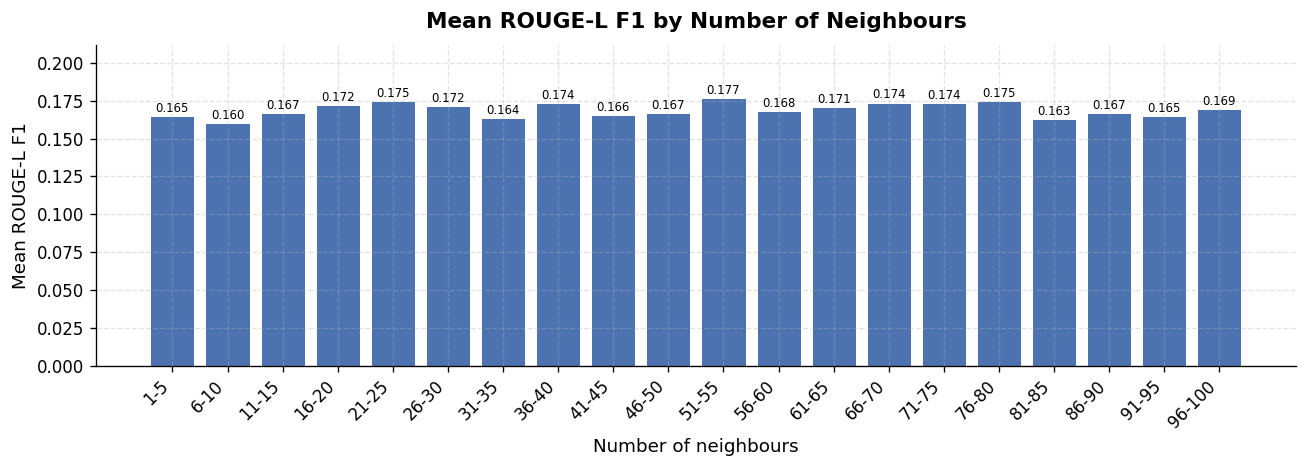

In [14]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

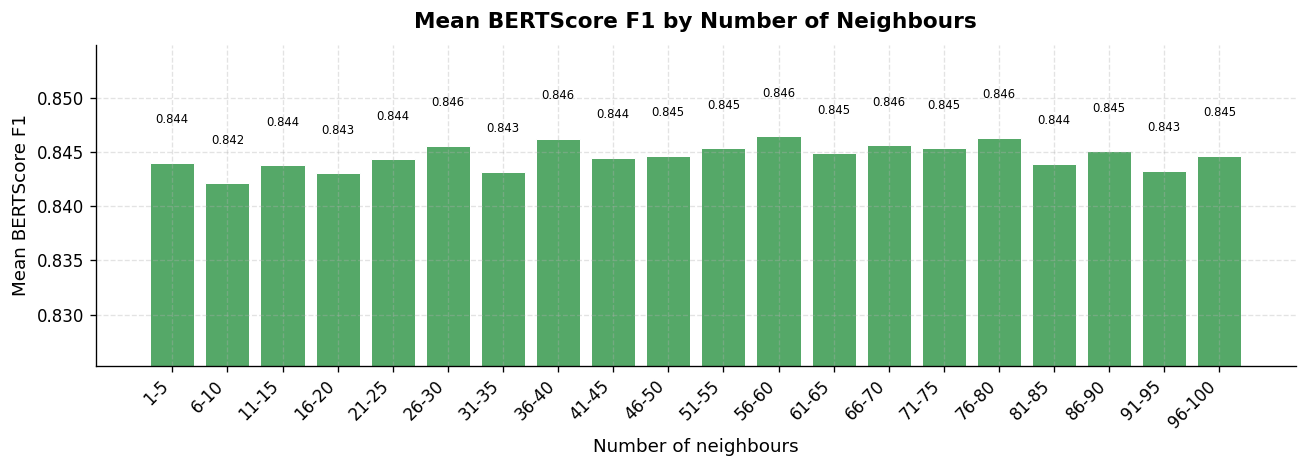

In [15]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

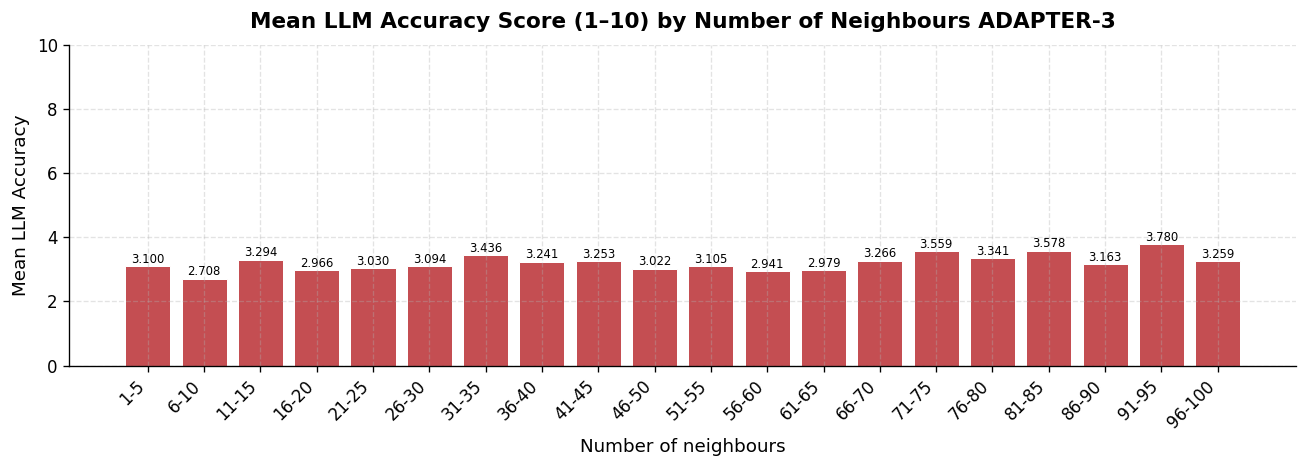

3.2137566137566136
3.0


In [16]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

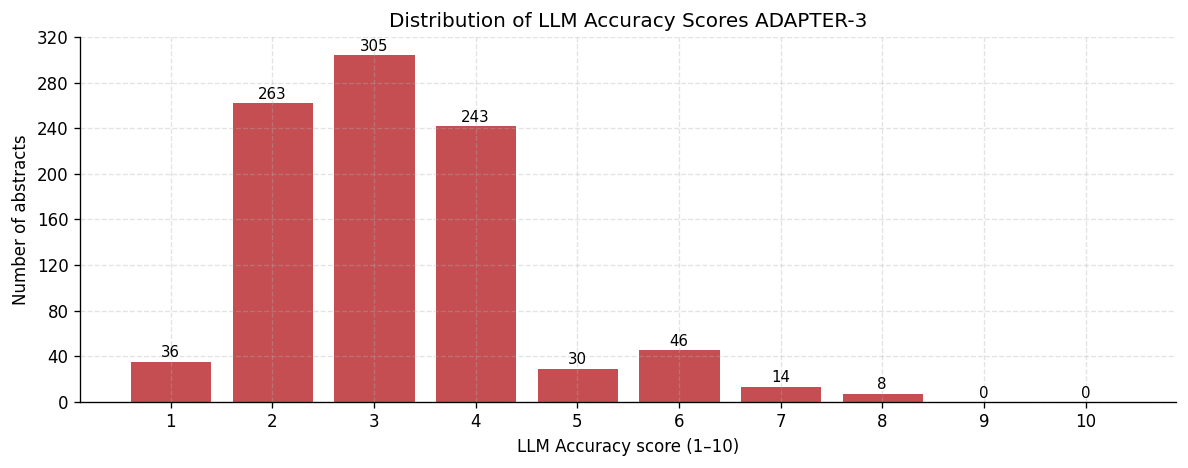

llm_accuracy
1      36
2     263
3     305
4     243
5      30
6      46
7      14
8       8
9       0
10      0
Name: count, dtype: int64

In [17]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

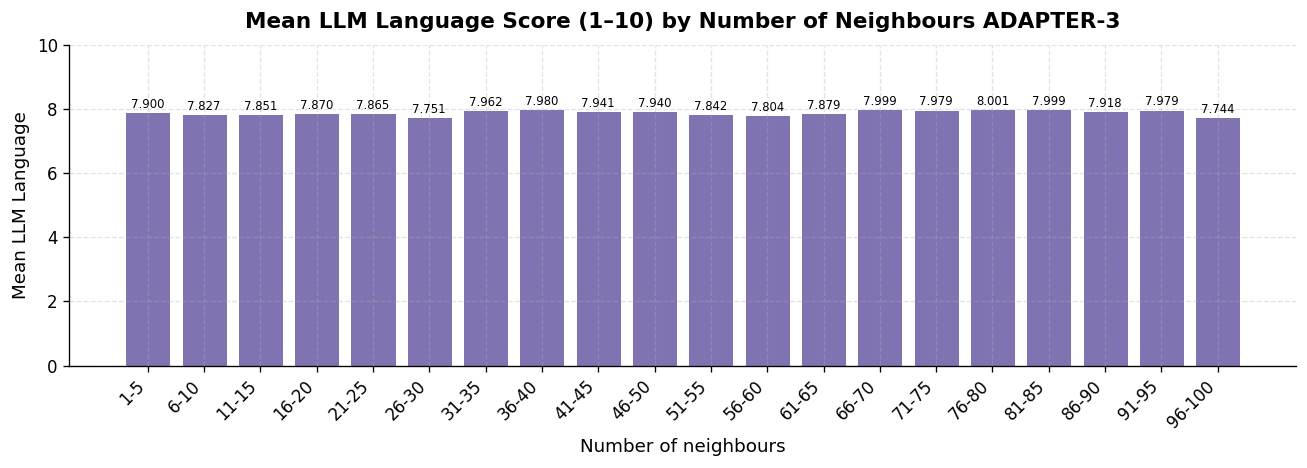

In [18]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

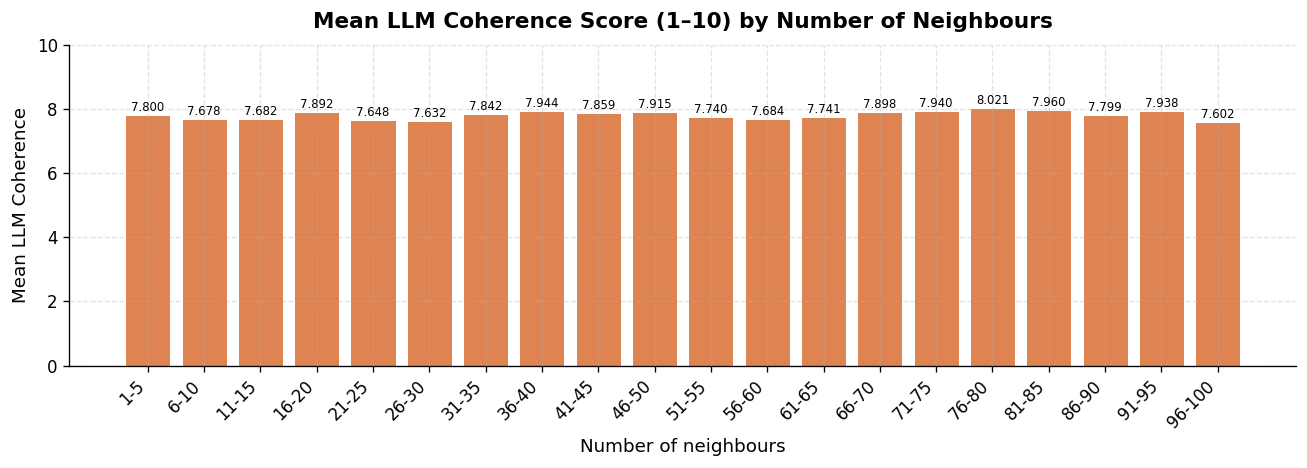

In [19]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

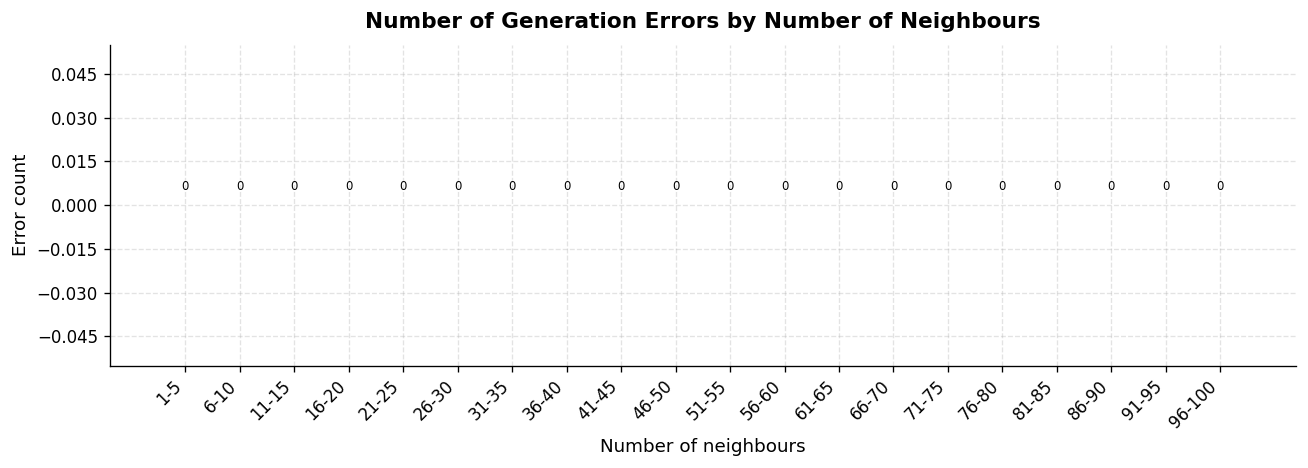

In [20]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [21]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_64393/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,169281,"Towards automated retinal screening, this paper makes an endeavor to simultaneously achieve pixel-level retinal lesion segmentation and image-level disease classification. Such a multi-task approach is crucial for accurate and clinically interpretable disease diagnosis. Prior art is insufficient due to three challenges, that is, lesions lacking objective boundaries, clinical importance of lesions irrelevant to their size, and the lack of one-to-one correspondence between lesion and disease classes. This paper attacks the three challenges in the context of diabetic retinopathy (DR) grading. We propose L-Net, a new variant of fully convolutional networks, with its expansive path re-designed to tackle the first challenge. A dual loss that leverages both semantic segmentation and image classification losses is devised to resolve the second challenge. We propose Side-Attention Net (SiAN) as our multi-task framework. Harnessing L-Net as a side-attention branch, SiAN simultaneously improves DR grading and interprets the decision with lesion maps. A set of 12K fundus images is manually segmented by 45 ophthalmologists for 8 DR-related lesions, resulting in 290K manual segments in total. Extensive experiments on this large-scale dataset show that our proposed approach surpasses the prior art for multiple tasks including lesion segmentation, lesion classification and DR grading.","Recently, several approaches have been proposed to solve the semantic segmentation problem. Among them, the U-",1
1,157497,"In recent years, much research effort on recommendation has been devoted to mining user behaviors, i.e., collaborative filtering, along with the general information which describes users or items, e.g., textual attributes, categorical demographics, product images, and so on. Price, an important factor in marketing --- which determines whether a user will make the final purchase decision on an item --- surprisingly, has received relatively little scrutiny. #R##N#In this work, we aim at developing an effective method to predict user purchase intention with the focus on the price factor in recommender systems. The main difficulties are two-fold: 1) the preference and sensitivity of a user on item price are unknown, which are only implicitly reflected in the items that the user has purchased, and 2) how the item price affects a user's intention depends largely on the product category, that is, the perception and affordability of a user on item price could vary significantly across categories. Towards the first difficulty, we propose to model the transitive relationship between user-to-item and item-to-price, taking the inspiration from the recently developed Graph Convolution Networks (GCN). The key idea is to propagate the influence of price on users with items as the bridge, so as to make the learned user representations be price-aware. For the second difficulty, we further integrate item categories into the propagation progress and model the possible pairwise interactions for predicting user-item interactions. We conduct extensive experiments on two real-world datasets, demonstrating the effectiveness of our GCN-based method in learning the price-aware preference of users. Further analysis reveals that modeling the price awareness is particularly useful for predicting user preference on items of unexplored categories.","Recommender systems play a vital role in today's online services. They help users discover interesting content and increase their engagement. Traditional collaborative filtering algorithms rely heavily on user-item interactions, which are often sparse and incomplete. To address this issue, many deep learning based methods have been proposed to learn rich and meaningful representations of users and items. These methods aim to capture the intrinsic relationships among users, items, and interactions. However, most of them suffer from the curse of dimensionali

In [22]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


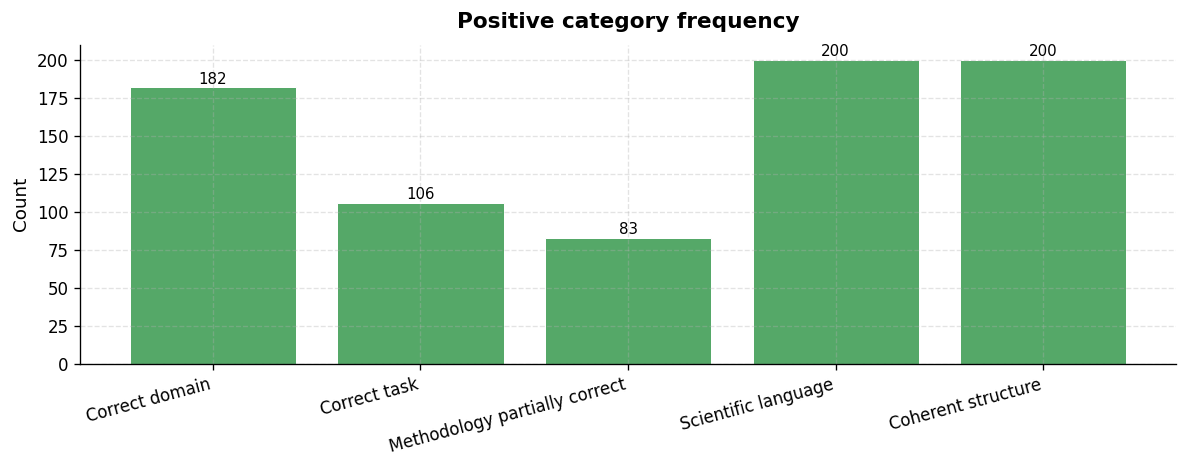

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()